In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import wordcloud
from textblob import TextBlob
# from tensorflow.keras.preprocessing.text import Tokenizer
from nltk.sentiment.util import *
import jenkspy
nltk.download('stopwords')
nltk.download('wordnet')
lm = WordNetLemmatizer()

    

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/ghazalehzehtab/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/ghazalehzehtab/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [3]:
trump_tweets = pd.read_csv('Data/trump_df_civility_lables.csv')
trump_tweets

,user_id,likes,retweet_count,cleantext,class
0,1.932939e+07,206.0,12.0,without doubt fourseasons debacle best part do...,2
1,1.575428e+07,56.0,16.0,president donald trump youngest daughter tiffa...,2
2,2.664201e+07,695.0,291.0,woah read article president debt donald trump ...,2
3,1.744662e+07,149.0,15.0,latest episode snl tackled donaldtrump loss co...,2
4,1.744662e+07,83.0,10.0,nataliemorales explains latinx voter supported...,2
...,...,...,...,...,...
209923,9.744188e+17,2.0,0.0,donaldtrump killing america votehimout,1
209924,1.319730e+18,0.0,0.0,watching poor guy foxnews explain reality trum...,2
209925,1.312579e+18,0.0,0.0,trump losing reelection trump biden presidentt...,2
209926,1.313286e+18,0.0,0.0,kayleigh mcenany trump brings big gun kayleigh...,2


In [4]:
def user_activity(dataframe):
    tweet_counts = dataframe.groupby('user_id').size()
    labels = tweet_counts.apply(lambda x: 'active' if x > 5 else 'less active')
    dataframe['user_activity'] = dataframe['user_id'].map(labels)
    return dataframe

def getsubjectivity(text):
    return TextBlob(text).sentiment.subjectivity
def getpolarity(text):
    return TextBlob(text).sentiment.polarity
def getAnalysis(score):
    if score <0:
        return 'negative'
    elif score == 0:
        return 'neutral'
    else:
        return 'positive'
def sentiment_analysis(tweets):
    tweets['subjectivity'] = tweets['cleantext'].apply(getsubjectivity)
    
    tweets['polarity'] = tweets['cleantext'].apply(getpolarity)
    
    tweets['analysis'] = tweets['polarity'].apply(getAnalysis)
    return tweets
def check_and_convert(value):
    if isinstance(value, float):  # Check if the value is a float
        return str(value)         # Convert float to string
    else:
        return value              # Return value unchanged if not a float


trump_tweets_activity = user_activity(trump_tweets)

In [5]:
trump_tweets_activity[trump_tweets_activity['user_activity'] == 'active'].head()

,user_id,likes,retweet_count,cleantext,class,user_activity
3,17446621.0,149.0,15.0,latest episode snl tackled donaldtrump loss co...,2,active
4,17446621.0,83.0,10.0,nataliemorales explains latinx voter supported...,2,active
5,17446621.0,99.0,21.0,actress nataliemorales explained latinx voter ...,2,active
6,17446621.0,73.0,1.0,jimmykimmel offered view last day gone close r...,2,active
7,17446621.0,756.0,42.0,ladygaga fired back donaldtrump team happy im ...,2,active


In [6]:
print("trump active user",trump_tweets_activity[trump_tweets_activity['user_activity'] == 'active'].shape)
print("trump less active user",trump_tweets_activity[trump_tweets_activity['user_activity'] == 'less active'].shape)

trump active user (144606, 6)
trump less active user (65322, 6)


In [8]:
trump_tweets_activity['cleantext'] = trump_tweets_activity['cleantext'].apply(lambda x: check_and_convert(x))
trump_df = sentiment_analysis(trump_tweets_activity)
trump_df.head()

,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis
0,19329393.0,206.0,12.0,without doubt fourseasons debacle best part do...,2,less active,0.483333,0.333333,positive
1,15754281.0,56.0,16.0,president donald trump youngest daughter tiffa...,2,less active,0.000000,0.000000,neutral
2,26642006.0,695.0,291.0,woah read article president debt donald trump ...,2,less active,0.000000,0.000000,neutral
3,17446621.0,149.0,15.0,latest episode snl tackled donaldtrump loss co...,2,active,0.800000,-0.033333,negative
4,17446621.0,83.0,10.0,nataliemorales explains latinx voter supported...,2,active,0.627778,-0.050000,negative


In [9]:
sorted_trump = trump_df.sort_values(by=['likes', 'retweet_count'], ascending=False)
sorted_trump.head()

,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis
22756,38362690.0,74084.0,20491.0,america assembled joebiden kamalaharris barack...,2,less active,0.000000,0.000000,neutral
216,47293791.0,35449.0,6629.0,call california joe biden minute poll closed e...,1,active,0.250000,-0.183333,negative
1179,212674482.0,25987.0,5986.0,white house still released health care plan mi...,2,less active,0.000000,0.000000,neutral
133,139823781.0,23225.0,1851.0,trump want throw military ballot bone spur,2,active,0.100000,-0.100000,negative
215,47293791.0,23037.0,2652.0,black trump showed election electionday electi...,1,active,0.433333,-0.166667,negative


In [10]:
trump_df.analysis.value_counts()

analysis
neutral     90575
positive    71600
negative    47753
Name: count, dtype: int64

In [11]:
trump_df['class'].value_counts()

class
2    142262
1     67413
0       253
Name: count, dtype: int64

In [12]:
num_bins = 5

breaks = jenkspy.jenks_breaks(sorted_trump['likes'], n_classes= num_bins)
print(breaks)
sorted_trump['likes_category'] = pd.cut(sorted_trump['likes'], bins=breaks, labels=range(1, num_bins+1), include_lowest=True)
sorted_trump.head(1000)

[0.0, 1319.0, 5992.0, 14894.0, 35449.0, 74084.0]


,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis,likes_category
22756,38362690.0,74084.0,20491.0,america assembled joebiden kamalaharris barack...,2,less active,0.000000,0.000000,neutral,5
216,47293791.0,35449.0,6629.0,call california joe biden minute poll closed e...,1,active,0.250000,-0.183333,negative,4
1179,212674482.0,25987.0,5986.0,white house still released health care plan mi...,2,less active,0.000000,0.000000,neutral,4
133,139823781.0,23225.0,1851.0,trump want throw military ballot bone spur,2,active,0.100000,-0.100000,negative,4
215,47293791.0,23037.0,2652.0,black trump showed election electionday electi...,1,active,0.433333,-0.166667,negative,4
...,...,...,...,...,...,...,...,...,...,...
1649,299273962.0,244.0,98.0,life home line make snide comment raking fores...,2,active,0.000000,0.000000,neutral,1
864,14179819.0,244.0,31.0,supporter rallied president donald trump n j t...,2,less active,0.000000,0.000000,neutral,1
1722,33529092.0,243.0,201.0,privilege living nation men made huge sacrific...,2,active,0.850000,0.400000,positive,1
695,499073990.0,243.0,79.0,trump worst job president u history trumpfaile...,2,active,1.000000,-1.000000,negative,1


In [13]:
breaks = jenkspy.jenks_breaks(sorted_trump['retweet_count'], n_classes= num_bins)
print(breaks)
sorted_trump['retweet_count_category'] = pd.cut(sorted_trump['retweet_count'], bins=breaks, labels=range(1, num_bins+1), include_lowest=True)
sorted_trump.head(1000)

[0.0, 277.0, 1382.0, 3640.0, 9572.0, 20491.0]


,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis,likes_category,retweet_count_category
22756,38362690.0,74084.0,20491.0,america assembled joebiden kamalaharris barack...,2,less active,0.000000,0.000000,neutral,5,5
216,47293791.0,35449.0,6629.0,call california joe biden minute poll closed e...,1,active,0.250000,-0.183333,negative,4,4
1179,212674482.0,25987.0,5986.0,white house still released health care plan mi...,2,less active,0.000000,0.000000,neutral,4,4
133,139823781.0,23225.0,1851.0,trump want throw military ballot bone spur,2,active,0.100000,-0.100000,negative,4,3
215,47293791.0,23037.0,2652.0,black trump showed election electionday electi...,1,active,0.433333,-0.166667,negative,4,3
...,...,...,...,...,...,...,...,...,...,...,...
1649,299273962.0,244.0,98.0,life home line make snide comment raking fores...,2,active,0.000000,0.000000,neutral,1,1
864,14179819.0,244.0,31.0,supporter rallied president donald trump n j t...,2,less active,0.000000,0.000000,neutral,1,1
1722,33529092.0,243.0,201.0,privilege living nation men made huge sacrific...,2,active,0.850000,0.400000,positive,1,1
695,499073990.0,243.0,79.0,trump worst job president u history trumpfaile...,2,active,1.000000,-1.000000,negative,1,1


In [14]:
sorted_trump.to_csv('sorted_trump_categorical_civility.csv', index=False)

In [15]:
sorted_trump.groupby('retweet_count_category')['polarity'].mean()

/var/folders/x5/k2wknhr57b1bk7btjrfpvfbm0000gn/T/ipykernel_28121/2088847216.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sorted_trump.groupby('retweet_count_category')['polarity'].mean()


retweet_count_category
1    0.040671
2    0.064406
3    0.042273
4   -0.020833
5    0.000000
Name: polarity, dtype: float64

In [16]:
sorted_trump.retweet_count_category.value_counts()

retweet_count_category
1    209671
2       211
3        38
4         7
5         1
Name: count, dtype: int64

In [17]:
sorted_trump.likes_category.value_counts()

likes_category
1    209742
2       137
3        36
4        12
5         1
Name: count, dtype: int64

In [18]:
sorted_trump.user_id.value_counts()

user_id
4.132841e+06    980
2.395433e+07    921
2.086079e+08    852
1.154952e+18    785
9.751178e+17    709
               ... 
1.044009e+18      1
7.392226e+17      1
8.645958e+07      1
3.600768e+08      1
1.199171e+18      1
Name: count, Length: 48169, dtype: int64

In [19]:
grouped_trump = sorted_trump.groupby(['user_id', 'analysis']).size().unstack(fill_value=0)
grouped_trump['Total_tweets'] = grouped_trump['positive'] + grouped_trump['negative']+grouped_trump['neutral']
grouped_trump ['user_polarization'] = ((grouped_trump['positive']-grouped_trump['negative']) * (
            grouped_trump['Total_tweets'] - grouped_trump['neutral'])) / pow(grouped_trump['Total_tweets'],2)
grouped_trump

analysis,negative,neutral,positive,Total_tweets,user_polarization
user_id,,,,,
5.310000e+02,0,0,1,1,1.000000
2.654000e+03,6,4,7,17,0.044983
3.471000e+03,0,0,1,1,1.000000
1.341000e+04,0,0,1,1,1.000000
1.341300e+04,2,0,3,5,0.200000
...,...,...,...,...,...
1.325492e+18,0,1,0,1,0.000000
1.325492e+18,0,1,0,1,0.000000
1.325521e+18,0,0,1,1,1.000000


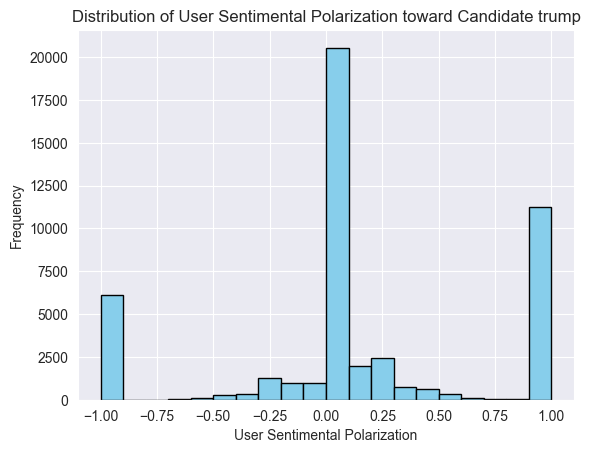

In [20]:
plt.hist(grouped_trump['user_polarization'], bins=20, color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('User Sentimental Polarization')
plt.ylabel('Frequency')
plt.title('Distribution of User Sentimental Polarization toward Candidate trump')
plt.savefig('user_polarization_distribution.png')
# Show the plot
plt.show()

# Civility

In [21]:
sorted_trump.head()

,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis,likes_category,retweet_count_category
22756,38362690.0,74084.0,20491.0,america assembled joebiden kamalaharris barack...,2,less active,0.000000,0.000000,neutral,5,5
216,47293791.0,35449.0,6629.0,call california joe biden minute poll closed e...,1,active,0.250000,-0.183333,negative,4,4
1179,212674482.0,25987.0,5986.0,white house still released health care plan mi...,2,less active,0.000000,0.000000,neutral,4,4
133,139823781.0,23225.0,1851.0,trump want throw military ballot bone spur,2,active,0.100000,-0.100000,negative,4,3
215,47293791.0,23037.0,2652.0,black trump showed election electionday electi...,1,active,0.433333,-0.166667,negative,4,3


In [22]:
sorted_trump.groupby('class')['polarity'].mean()

class
0   -0.080968
1    0.004150
2    0.058225
Name: polarity, dtype: float64

In [23]:
sorted_trump.groupby('class')['subjectivity'].mean()

class
0    0.377773
1    0.366062
2    0.297371
Name: subjectivity, dtype: float64

In [24]:
final_trump= sorted_trump.groupby('user_id').agg({'class': 'mean', 'polarity': 'mean', 'likes': 'sum', 'retweet_count': 'sum'})

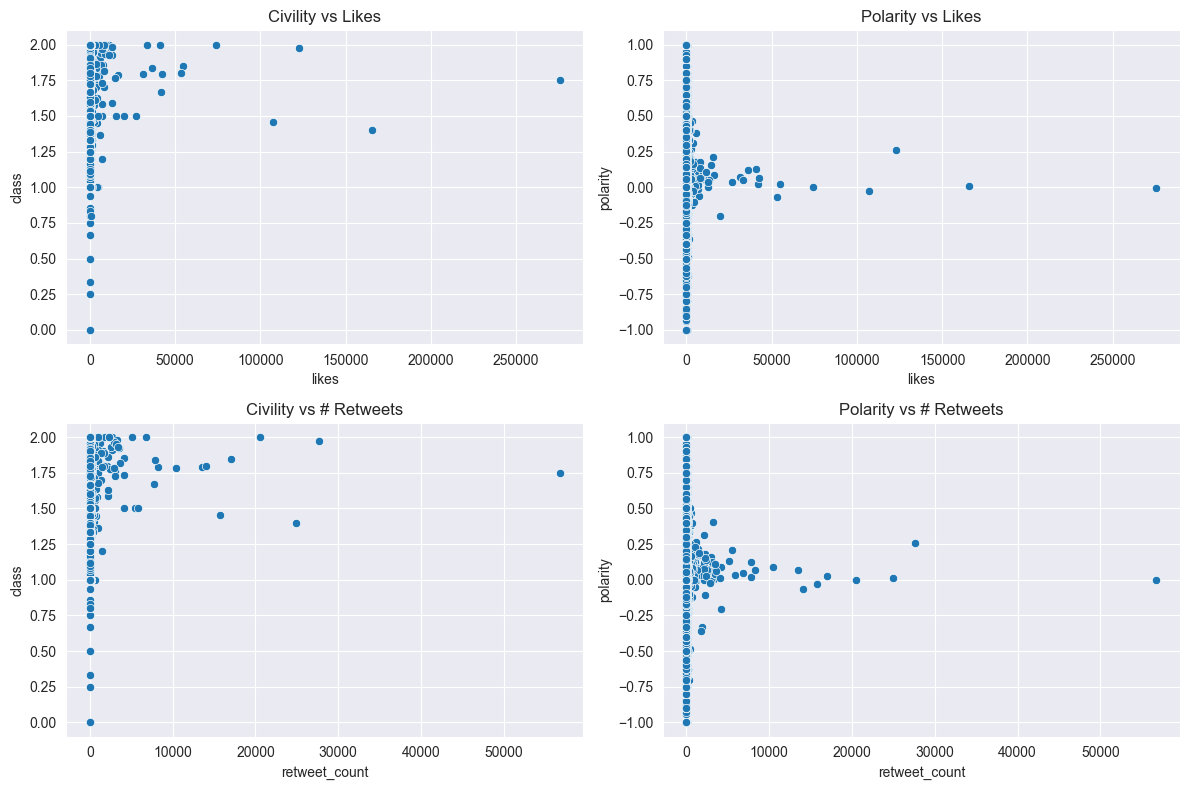

In [25]:

# Scatter plot for civility (class) vs likes and polarity vs likes
plt.figure(figsize=(12, 8))

# Civility vs Likes
plt.subplot(2, 2, 1)
sns.scatterplot(x='likes', y='class', data=final_trump)
plt.title('Civility vs Likes')

# Polarity vs Likes
plt.subplot(2, 2, 2)
sns.scatterplot(x='likes', y='polarity', data=final_trump)
plt.title('Polarity vs Likes')

plt.subplot(2, 2, 3)
sns.scatterplot(x='retweet_count', y='class', data=final_trump)
plt.title('Civility vs # Retweets')

plt.subplot(2, 2, 4)
sns.scatterplot(x='retweet_count', y='polarity', data=final_trump)
plt.title('Polarity vs # Retweets')

plt.tight_layout()  # Adjust layout to prevent overlap

# Save the combined plot
plt.savefig('combined_scatter_plots_trump.png')
plt.show()

In [26]:

final_trump_filtered = final_trump[ (final_trump['retweet_count'] < 40000) & (final_trump['class'] > 0.001) & (final_trump['likes'] < 400000)]

final_trump_filtered

,class,polarity,likes,retweet_count
user_id,,,,
5.310000e+02,1.000000,0.166667,0.0,0.0
2.654000e+03,1.705882,-0.056944,8.0,0.0
3.471000e+03,2.000000,0.350000,5.0,0.0
1.341000e+04,2.000000,0.080556,4.0,0.0
1.341300e+04,1.800000,0.102500,47.0,7.0
...,...,...,...,...
1.325492e+18,2.000000,0.000000,0.0,0.0
1.325492e+18,2.000000,0.000000,0.0,0.0
1.325521e+18,1.000000,0.500000,1.0,0.0


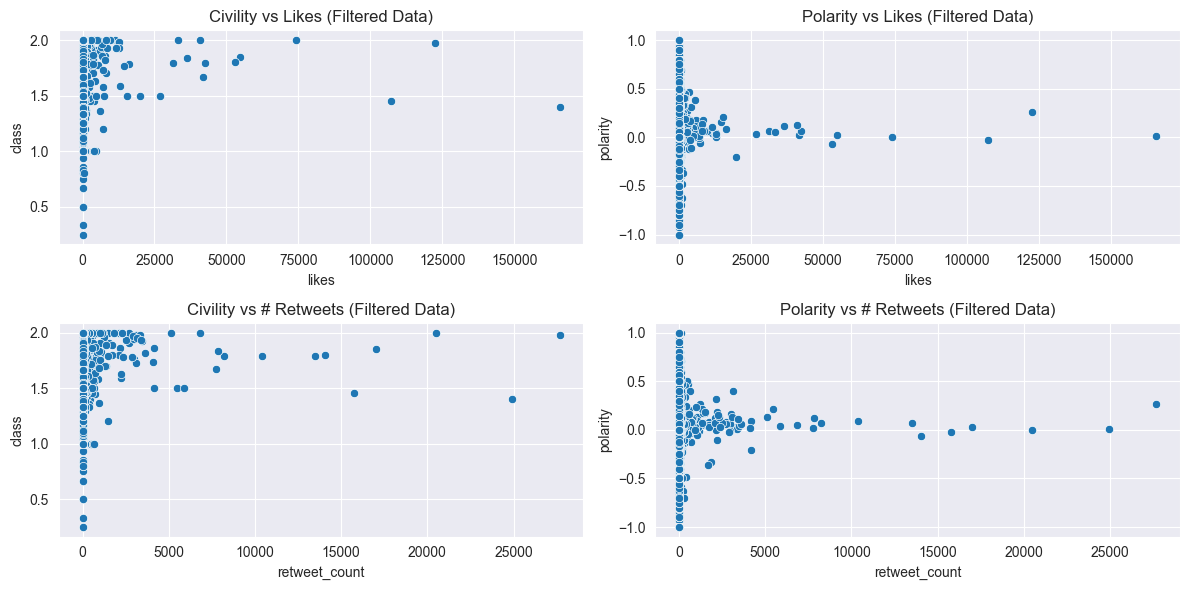

In [27]:
plt.figure(figsize=(12, 6))

# Civility vs Likes (Filtered Data)
plt.subplot(2, 2, 1)
sns.scatterplot(x='likes', y='class', data=final_trump_filtered)
plt.title('Civility vs Likes (Filtered Data)')

# Polarity vs Likes (Filtered Data)
plt.subplot(2, 2, 2)
sns.scatterplot(x='likes', y='polarity', data=final_trump_filtered)
plt.title('Polarity vs Likes (Filtered Data)')

plt.subplot(2, 2, 3)
sns.scatterplot(x='retweet_count', y='class', data=final_trump_filtered)
plt.title('Civility vs # Retweets (Filtered Data)')

plt.subplot(2, 2, 4)
sns.scatterplot(x='retweet_count', y='polarity', data=final_trump_filtered)
plt.title('Polarity vs # Retweets (Filtered Data)')

plt.tight_layout()  # Adjust layout to prevent overlap

# Save the combined plot for filtered data
plt.savefig('combined_scatter_plots_filtered.png')
plt.show()


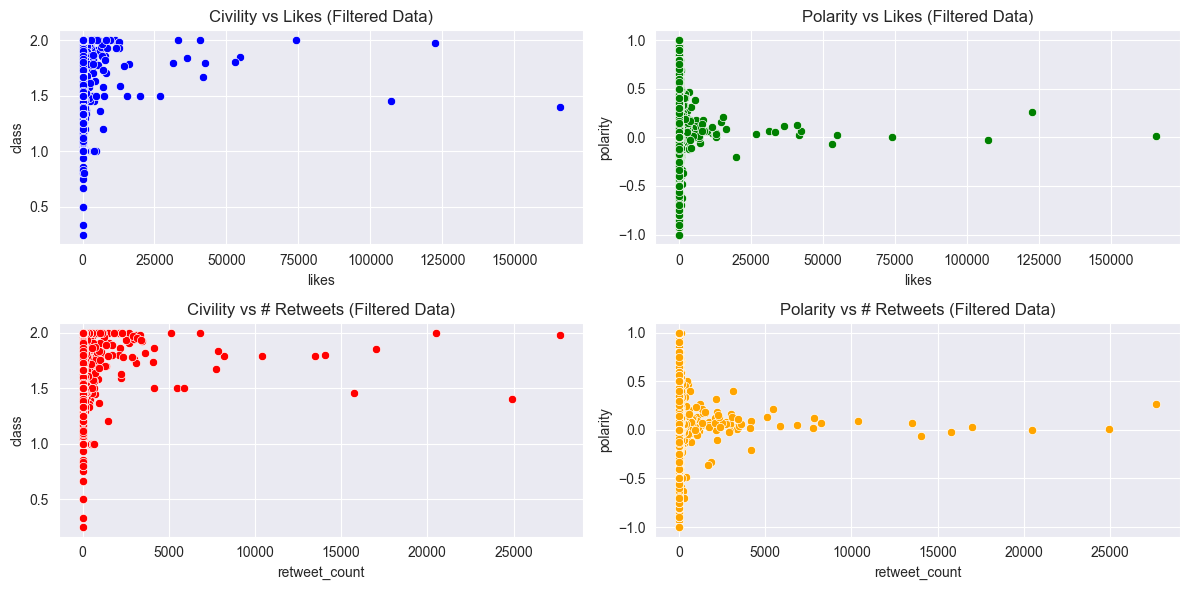

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

# Civility vs Likes (Filtered Data)
plt.subplot(2, 2, 1)
sns.scatterplot(x='likes', y='class', color='blue', data=final_trump_filtered)
plt.title('Civility vs Likes (Filtered Data)')

# Polarity vs Likes (Filtered Data)
plt.subplot(2, 2, 2)
sns.scatterplot(x='likes', y='polarity', color='green', data=final_trump_filtered)
plt.title('Polarity vs Likes (Filtered Data)')

plt.subplot(2, 2, 3)
sns.scatterplot(x='retweet_count', y='class', color='red', data=final_trump_filtered)
plt.title('Civility vs # Retweets (Filtered Data)')

plt.subplot(2, 2, 4)
sns.scatterplot(x='retweet_count', y='polarity', color='orange', data=final_trump_filtered)
plt.title('Polarity vs # Retweets (Filtered Data)')

plt.tight_layout()  # Adjust layout to prevent overlap

# Save the combined plot for filtered data
plt.savefig('combined_scatter_plots_filtered_trump_color.png')
plt.show()